In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
import zipfile

zip_path = "/content/food_dataset.zip"
extract_path = "/content/food_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction terminée !")

Extraction terminée !


In [ ]:
path = "/content/food_dataset/food_dataset"

for root, dirs, files in os.walk(path):
    print(f"Dossier : {root}")
    print(f"Sous-dossiers : {dirs}")
    print(f"Nombre de fichiers : {len(files)}")
    print("-" * 50)

Dossier : /content/food_dataset/food_dataset
Sous-dossiers : ['train', 'val', 'test']
Nombre de fichiers : 0
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/train
Sous-dossiers : ['corba', 'donat', 'makarna']
Nombre de fichiers : 0
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/train/corba
Sous-dossiers : []
Nombre de fichiers : 320
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/train/donat
Sous-dossiers : []
Nombre de fichiers : 320
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/train/makarna
Sous-dossiers : []
Nombre de fichiers : 320
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/val
Sous-dossiers : ['corba', 'donat', 'makarna']
Nombre de fichiers : 0
--------------------------------------------------
Dossier : /content/food_dataset/food_datas

In [ ]:
train_path = "/content/food_dataset/food_dataset/train"
val_path = "/content/food_dataset/food_dataset/val"

for dataset_path in [train_path, val_path]:

    print(f"\nDataset : {dataset_path}")

    for classe in os.listdir(dataset_path):

        classe_path = os.path.join(dataset_path, classe)

        if os.path.isdir(classe_path):
            images = os.listdir(classe_path)

            print(f"{classe} : {len(images)} images")


Dataset : /content/food_dataset/food_dataset/train
corba : 320 images
donat : 320 images
makarna : 320 images

Dataset : /content/food_dataset/food_dataset/val
corba : 80 images
donat : 80 images
makarna : 80 images


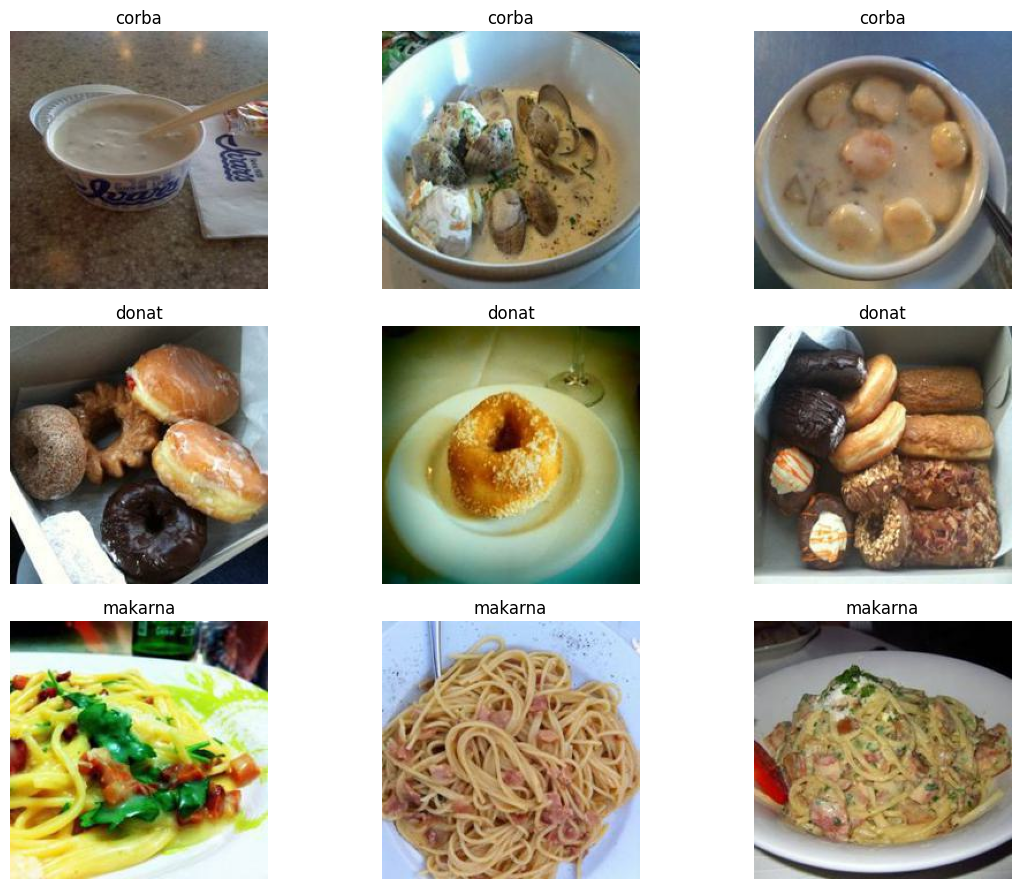

In [ ]:
import random
from tensorflow.keras.utils import load_img

classes = ['corba', 'donat', 'makarna']

plt.figure(figsize=(12, 9))

for i, classe in enumerate(classes):

    classe_path = os.path.join(train_path, classe)
    images = os.listdir(classe_path)

    selected_images = random.sample(images, 3)

    for j, image_name in enumerate(selected_images):

        img_path = os.path.join(classe_path, image_name)
        img = load_img(img_path, target_size=(224, 224))

        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(img)
        plt.title(classe)
        plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
tf.keras.utils.set_random_seed(42)

In [ ]:
preprocess_input = tf.keras.applications.resnet50.preprocess_input

In [ ]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)

In [ ]:
val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [ ]:
train_gen = train_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

val_gen = val_datagen.flow_from_directory(
    val_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 960 images belonging to 3 classes.
Found 240 images belonging to 3 classes.


In [ ]:
print(train_gen.class_indices)

{'corba': 0, 'donat': 1, 'makarna': 2}


In [ ]:
test_path = os.path.join(path, "test")

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_gen = test_datagen.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 240 images belonging to 3 classes.


Found 960 images belonging to 3 classes.


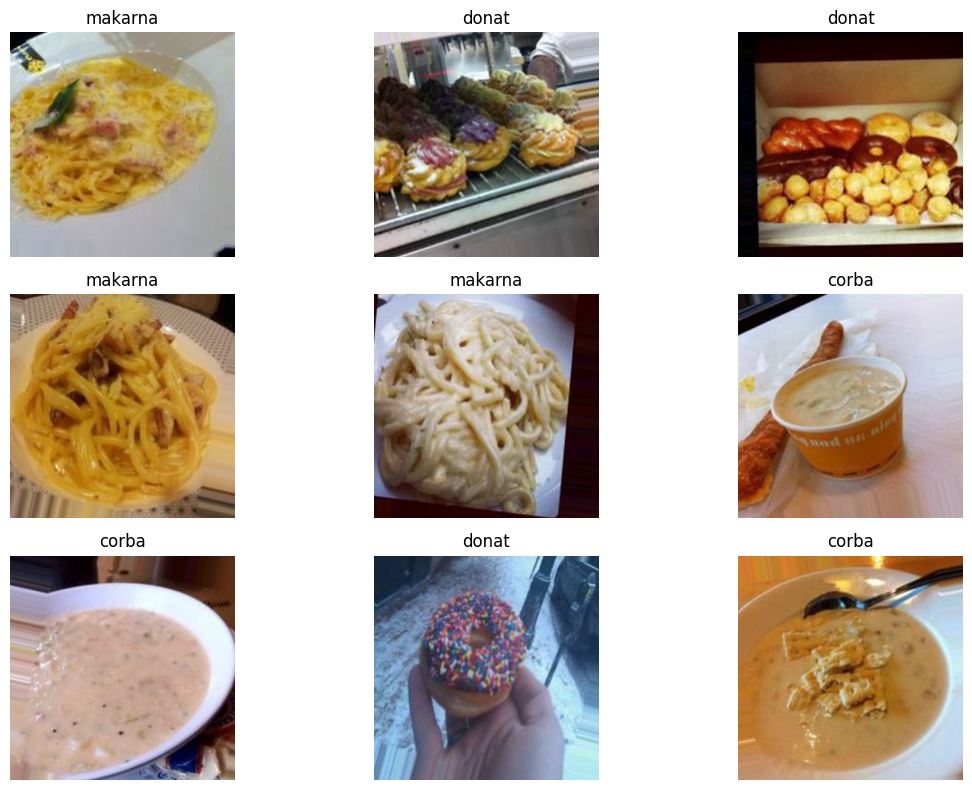

In [ ]:
# Générateur temporaire pour visualiser les augmentations
visual_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)

visual_gen = visual_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=9,
    class_mode='categorical',
    shuffle=True
)

# Récupérer un batch d'images augmentées
images, labels = next(visual_gen)

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].astype("uint8"))
    classe_index = np.argmax(labels[i])
    classe = list(train_gen.class_indices.keys())[classe_index]
    plt.title(classe)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Charger ResNet50
base = tf.keras.applications.ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Construction du modèle
nb_classes = len(train_gen.class_indices)

model = tf.keras.Sequential([
    base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(
        nb_classes,
        activation='softmax'
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
total_params = model.count_params()
trainable_params = sum(
    np.prod(w.shape) for w in model.trainable_weights
)

non_trainable_params = total_params - trainable_params

percentage = (trainable_params / total_params) * 100

print("Paramètres totaux :", total_params)
print("Paramètres entraînables :", trainable_params)
print("Paramètres non entraînables :", non_trainable_params)
print(f"Pourcentage entraînable : {percentage:.4f}%")

Paramètres totaux : 23593859
Paramètres entraînables : 6147
Paramètres non entraînables : 23587712
Pourcentage entraînable : 0.0261%


In [ ]:
# compiler
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# Entrainement
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.8458 - loss: 0.3952 - val_accuracy: 0.9292 - val_loss: 0.1591
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 15s 486ms/step - accuracy: 0.9625 - loss: 0.1176 - val_accuracy: 0.9375 - val_loss: 0.1498
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 481ms/step - accuracy: 0.9708 - loss: 0.0897 - val_accuracy: 0.9458 - val_loss: 0.1270
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 15s 493ms/step - accuracy: 0.9760 - loss: 0.0735 - val_accuracy: 0.9458 - val_loss: 0.1236
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 15s 485ms/step - accuracy: 0.9760 - loss: 0.0662 - val_accuracy: 0.9583 - val_loss: 0.1219
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 473ms/step - accuracy: 0.9854 - loss: 0.0516 - val_accuracy: 0.9500 - val_loss: 0.1162
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 476ms/step - accuracy: 0.9896 - loss: 0.0453 - val_accuracy: 0.9500 - val_loss: 0.1337
Epoch 8/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 478ms/step - accuracy: 0.9937 - loss: 0.0360 - val_accurac

In [ ]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']

train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

In [ ]:
for epoch in range(10):
    print(f"Epoch {epoch + 1}")
    print(f"Train Loss      : {train_loss[epoch]:.4f}")
    print(f"Validation Loss : {val_loss[epoch]:.4f}")
    print(f"Train Accuracy  : {train_accuracy[epoch]:.4f}")
    print(f"Val Accuracy    : {val_accuracy[epoch]:.4f}")
    print("-" * 40)

Epoch 1
Train Loss      : 0.3952
Validation Loss : 0.1591
Train Accuracy  : 0.8458
Val Accuracy    : 0.9292
----------------------------------------
Epoch 2
Train Loss      : 0.1176
Validation Loss : 0.1498
Train Accuracy  : 0.9625
Val Accuracy    : 0.9375
----------------------------------------
Epoch 3
Train Loss      : 0.0897
Validation Loss : 0.1270
Train Accuracy  : 0.9708
Val Accuracy    : 0.9458
----------------------------------------
Epoch 4
Train Loss      : 0.0735
Validation Loss : 0.1236
Train Accuracy  : 0.9760
Val Accuracy    : 0.9458
----------------------------------------
Epoch 5
Train Loss      : 0.0662
Validation Loss : 0.1219
Train Accuracy  : 0.9760
Val Accuracy    : 0.9583
----------------------------------------
Epoch 6
Train Loss      : 0.0516
Validation Loss : 0.1162
Train Accuracy  : 0.9854
Val Accuracy    : 0.9500
----------------------------------------
Epoch 7
Train Loss      : 0.0453
Validation Loss : 0.1337
Train Accuracy  : 0.9896
Val Accuracy    : 0.950

In [ ]:
test_gen.reset()

test_loss, test_accuracy = model.evaluate(test_gen)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.9542 - loss: 0.1220
Test Loss     : 0.1220
Test Accuracy : 0.9542
Test Accuracy : 95.42%


In [ ]:
test_gen.reset()

predictions = model.predict(test_gen)

y_pred = np.argmax(predictions, axis=1)
y_true = test_gen.classes

8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 551ms/step


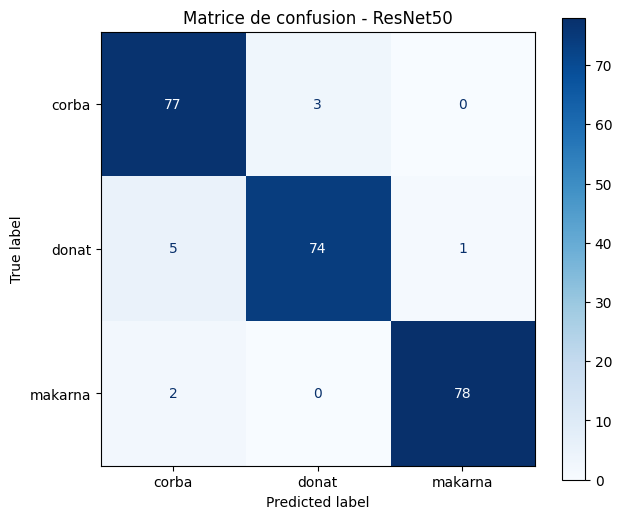

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = list(test_gen.class_indices.keys())

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap='Blues',
    ax=ax,
    values_format='d'
)

plt.title("Matrice de confusion - ResNet50")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

       corba       0.92      0.96      0.94        80
       donat       0.96      0.93      0.94        80
     makarna       0.99      0.97      0.98        80

    accuracy                           0.95       240
   macro avg       0.96      0.95      0.95       240
weighted avg       0.96      0.95      0.95       240



In [ ]:

import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    UpSampling2D, Concatenate, Activation
)
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split

print("TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices('GPU'))


TensorFlow : 2.21.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import zipfile

zip_path = "/content/PH2Dataset.zip"
extract_path = "/content/PH2dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction terminée !")

In [ ]:
path = "/content/PH2dataset/PH2Dataset"
for root, dirs, files_list in os.walk(path):
    level = root.replace(path, '').count(os.sep)

    if level <= 3:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files_list[:5]:
            print(f"{indent}    {file}")


PH2Dataset/
    masks/
        IMD058.png
        IMD331.png
        IMD211.png
        IMD284.png
        IMD400.png
    images/
        IMD058.png
        IMD331.png
        IMD211.png
        IMD284.png
        IMD400.png


In [ ]:

print("Chemin racine :", path)
print("\nContenu du dossier racine :")

for item in os.listdir(path):
    print(item)


Chemin racine : /content/PH2dataset/PH2Dataset

Contenu du dossier racine :
masks
images


In [ ]:

all_files = []

for root, dirs, files_list in os.walk(path):
    for file in files_list:
        all_files.append(os.path.join(root, file))

print("Nombre total de fichiers :", len(all_files))

for f in all_files[:30]:
    print(f)


Nombre total de fichiers : 400
/content/PH2dataset/PH2Dataset/masks/IMD058.png
/content/PH2dataset/PH2Dataset/masks/IMD331.png
/content/PH2dataset/PH2Dataset/masks/IMD211.png
/content/PH2dataset/PH2Dataset/masks/IMD284.png
/content/PH2dataset/PH2Dataset/masks/IMD400.png
/content/PH2dataset/PH2Dataset/masks/IMD101.png
/content/PH2dataset/PH2Dataset/masks/IMD421.png
/content/PH2dataset/PH2Dataset/masks/IMD392.png
/content/PH2dataset/PH2Dataset/masks/IMD196.png
/content/PH2dataset/PH2Dataset/masks/IMD016.png
/content/PH2dataset/PH2Dataset/masks/IMD197.png
/content/PH2dataset/PH2Dataset/masks/IMD064.png
/content/PH2dataset/PH2Dataset/masks/IMD200.png
/content/PH2dataset/PH2Dataset/masks/IMD411.png
/content/PH2dataset/PH2Dataset/masks/IMD142.png
/content/PH2dataset/PH2Dataset/masks/IMD176.png
/content/PH2dataset/PH2Dataset/masks/IMD430.png
/content/PH2dataset/PH2Dataset/masks/IMD418.png
/content/PH2dataset/PH2Dataset/masks/IMD304.png
/content/PH2dataset/PH2Dataset/masks/IMD065.png
/content/

In [ ]:

# Définir les dossiers
images_path = os.path.join(path, "images")
masks_path = os.path.join(path, "masks")

# Récupérer les fichiers PNG
image_files = glob.glob(os.path.join(images_path, "*.png"))
mask_files = glob.glob(os.path.join(masks_path, "*.png"))

# Construire les dictionnaires à partir des noms de fichiers
images_dict = {
    os.path.splitext(os.path.basename(f))[0]: f
    for f in image_files
}

masks_dict = {
    os.path.splitext(os.path.basename(f))[0]: f
    for f in mask_files
}

# Identifier les paires communes
common_ids = sorted(set(images_dict) & set(masks_dict))

print("Nombre d'images :", len(image_files))
print("Nombre de masques :", len(mask_files))
print("Images associées :", len(common_ids))

print("Images sans masque :", len(set(images_dict) - set(masks_dict)))
print("Masques sans image :", len(set(masks_dict) - set(images_dict)))

print("\nPremières correspondances :")

for image_id in common_ids[:5]:
    print(image_id)
    print("Image :", images_dict[image_id])
    print("Masque :", masks_dict[image_id])


Nombre d'images : 200
Nombre de masques : 200
Images associées : 200
Images sans masque : 0
Masques sans image : 0

Premières correspondances :
IMD002
Image : /content/PH2dataset/PH2Dataset/images/IMD002.png
Masque : /content/PH2dataset/PH2Dataset/masks/IMD002.png
IMD003
Image : /content/PH2dataset/PH2Dataset/images/IMD003.png
Masque : /content/PH2dataset/PH2Dataset/masks/IMD003.png
IMD004
Image : /content/PH2dataset/PH2Dataset/images/IMD004.png
Masque : /content/PH2dataset/PH2Dataset/masks/IMD004.png
IMD006
Image : /content/PH2dataset/PH2Dataset/images/IMD006.png
Masque : /content/PH2dataset/PH2Dataset/masks/IMD006.png
IMD008
Image : /content/PH2dataset/PH2Dataset/images/IMD008.png
Masque : /content/PH2dataset/PH2Dataset/masks/IMD008.png


Identifiant : IMD002


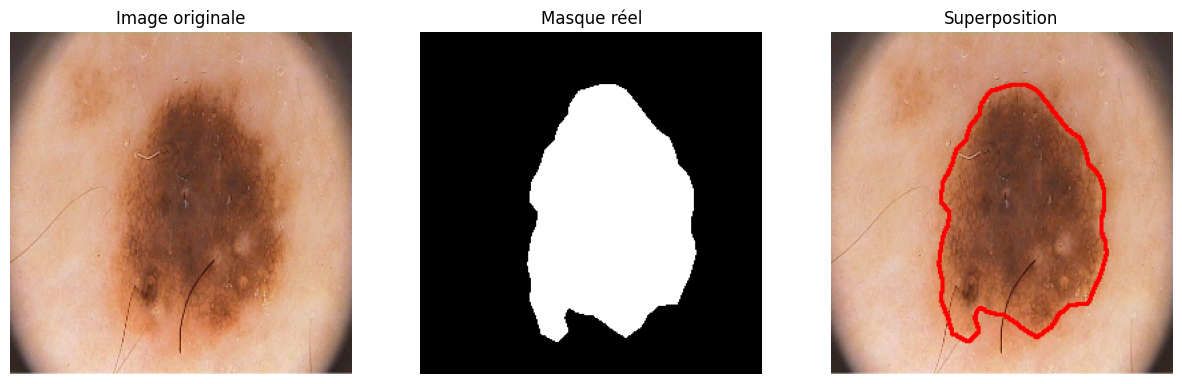

Identifiant : IMD085


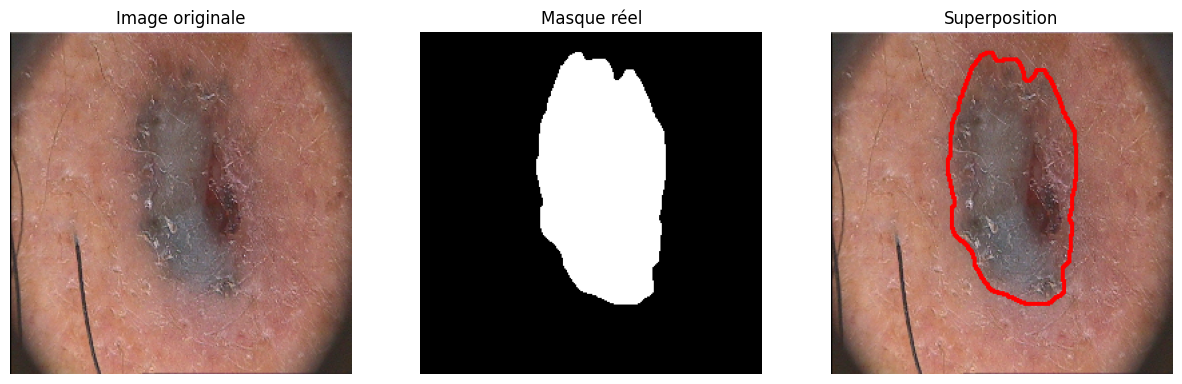

Identifiant : IMD379


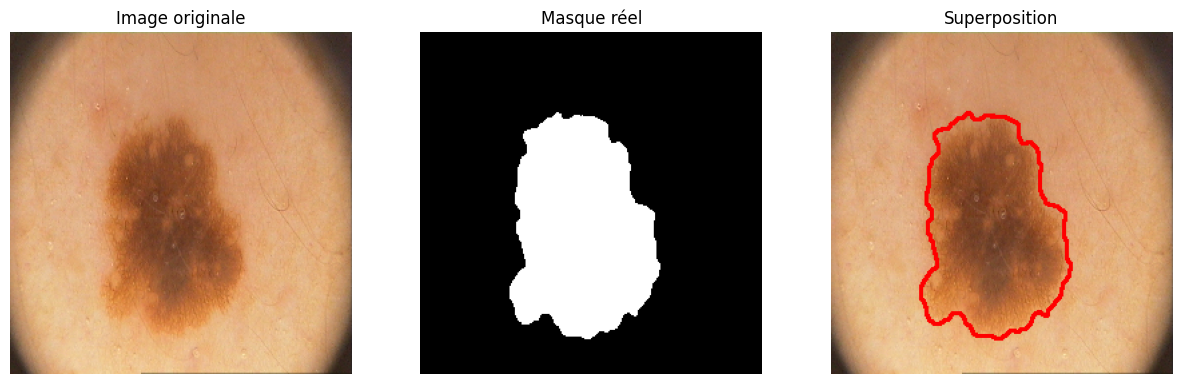

In [ ]:

def display_triplet(image_path, mask_path):

    # Charger l'image en couleur
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Charger le masque en niveaux de gris
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    # Redimensionner pour faciliter la visualisation
    image = cv2.resize(image, (256, 256))
    mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_NEAREST)

    # Créer la superposition
    overlay = image.copy()

    # Afficher le contour du masque en rouge
    contours, _ = cv2.findContours(
        (mask > 127).astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(overlay, contours, -1, (255, 0, 0), 2)

    # Affichage
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title("Image originale")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Masque réel")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title("Superposition")
    plt.axis("off")

    plt.show()


for idx in [0, 50, 150]:
    image_id = common_ids[idx]

    print("Identifiant :", image_id)

    display_triplet(
        images_dict[image_id],
        masks_dict[image_id]
    )


In [ ]:

IMG_SIZE = 256

X = []
Y = []

for image_id in common_ids:

    # 1. Charger l'image couleur
    img = cv2.imread(images_dict[image_id])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 2. Charger le masque en niveaux de gris
    mask = cv2.imread(
        masks_dict[image_id],
        cv2.IMREAD_GRAYSCALE
    )

    # 3. Redimensionner
    img = cv2.resize(
        img,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )

    mask = cv2.resize(
        mask,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_NEAREST
    )

    # 4. Normaliser l'image entre 0 et 1
    img = img.astype(np.float32) / 255.0

    # 5. Binariser le masque
    mask = (mask > 127).astype(np.float32)

    # 6. Ajouter une dimension au masque
    mask = np.expand_dims(mask, axis=-1)

    X.append(img)
    Y.append(mask)

# Conversion en tableaux NumPy
X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)

print("Dimensions des images :", X.shape)
print("Dimensions des masques :", Y.shape)

print("Min image :", X.min())
print("Max image :", X.max())

print("Valeurs du masque :", np.unique(Y))


Dimensions des images : (200, 256, 256, 3)
Dimensions des masques : (200, 256, 256, 1)
Min image : 0.0
Max image : 1.0
Valeurs du masque : [0. 1.]


In [ ]:

# Première séparation : 70% train et 30% temporaire
X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, Y,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

# Deuxième séparation : 15% validation et 15% test
X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

print("Train :", X_train.shape, Y_train.shape)
print("Validation :", X_val.shape, Y_val.shape)
print("Test :", X_test.shape, Y_test.shape)


Train : (140, 256, 256, 3) (140, 256, 256, 1)
Validation : (30, 256, 256, 3) (30, 256, 256, 1)
Test : (30, 256, 256, 3) (30, 256, 256, 1)


In [ ]:
""" Création du modele U-Net """

def conv_block(inputs, filters):

    x = Conv2D(
        filters,
        (3, 3),
        padding="same"
    )(inputs)

    x = Activation("relu")(x)

    x = Conv2D(
        filters,
        (3, 3),
        padding="same"
    )(x)

    x = Activation("relu")(x)

    return x


def decoder_block(inputs, skip, filters):

    # Agrandir la résolution
    x = UpSampling2D(size=(2, 2))(inputs)

    # Concaténer avec les caractéristiques de l'encodeur
    x = Concatenate()([x, skip])

    # Deux convolutions
    x = conv_block(x, filters)

    return x


In [ ]:

def build_unet(input_shape=(256, 256, 3)):

    inputs = Input(input_shape)

    # =========================
    # ENCODEUR
    # =========================

    c1 = conv_block(inputs, 32)
    p1 = MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128)
    p3 = MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 256)
    p4 = MaxPooling2D((2, 2))(c4)

    # =========================
    # BOTTLENECK
    # =========================

    b = conv_block(p4, 512)

    # =========================
    # DECODEUR
    # =========================

    d1 = decoder_block(b, c4, 256)

    d2 = decoder_block(d1, c3, 128)

    d3 = decoder_block(d2, c2, 64)

    d4 = decoder_block(d3, c1, 32)

    # =========================
    # SORTIE
    # =========================

    outputs = Conv2D(
        1,
        (1, 1),
        activation="sigmoid"
    )(d4)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="U-Net"
    )

    return model


model = build_unet()

print("Modèle U-Net construit avec succès !")


Modèle U-Net construit avec succès !


TP **5**

In [ ]:
import zipfile

zip_path = "/content/food_dataset.zip"
extract_path = "/content/food_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction terminée !")

Extraction terminée !


In [ ]:
import os
path = "/content/food_dataset/food_dataset"

for root, dirs, files in os.walk(path):
    print(f"Dossier : {root}")
    print(f"Sous-dossiers : {dirs}")
    print(f"Nombre de fichiers : {len(files)}")
    print("-" * 50)

Dossier : /content/food_dataset/food_dataset
Sous-dossiers : ['test', 'train', 'val']
Nombre de fichiers : 0
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/test
Sous-dossiers : ['donat', 'makarna', 'corba']
Nombre de fichiers : 0
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/test/donat
Sous-dossiers : []
Nombre de fichiers : 80
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/test/makarna
Sous-dossiers : []
Nombre de fichiers : 80
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/test/corba
Sous-dossiers : []
Nombre de fichiers : 80
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/train
Sous-dossiers : ['donat', 'makarna', 'corba']
Nombre de fichiers : 0
--------------------------------------------------
Dossier : /content/food_dataset/food_dataset/tr

In [ ]:
train_path = "/content/food_dataset/food_dataset/train"
val_path = "/content/food_dataset/food_dataset/val"

for dataset_path in [train_path, val_path]:

    print(f"\nDataset : {dataset_path}")

    for classe in os.listdir(dataset_path):

        classe_path = os.path.join(dataset_path, classe)

        if os.path.isdir(classe_path):
            images = os.listdir(classe_path)

            print(f"{classe} : {len(images)} images")


Dataset : /content/food_dataset/food_dataset/train
donat : 320 images
makarna : 320 images
corba : 320 images

Dataset : /content/food_dataset/food_dataset/val
donat : 80 images
makarna : 80 images
corba : 80 images


In [ ]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)

train_gen = train_datagen.flow_from_directory(
    train_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)
"""***************************"""
val_datagen = ImageDataGenerator(
)

val_gen = val_datagen.flow_from_directory(
    val_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 960 images belonging to 3 classes.
Found 240 images belonging to 3 classes.


In [ ]:
test_path = os.path.join(path, "test")

test_datagen = ImageDataGenerator()

test_gen = test_datagen.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 240 images belonging to 3 classes.


In [ ]:
print(train_gen.class_indices)

{'corba': 0, 'donat': 1, 'makarna': 2}


In [ ]:

import tensorflow as tf

# Charger EfficientNetB0 pré-entraîné sur ImageNet
base = tf.keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Geler toutes les couches
base.trainable = False

# Vérifier le gel des couches
print("Nombre total de couches :", len(base.layers))
print("Nombre de couches entraînables :",
      sum(layer.trainable for layer in base.layers))


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Nombre total de couches : 238
Nombre de couches entraînables : 0


In [ ]:

from tensorflow.keras import layers, models

# Nombre de classes
nb_classes = len(train_gen.class_indices)

# Construction du modèle
model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(nb_classes, activation='softmax')
])

# Afficher l'architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:

from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Modèle compilé avec succès !")


Modèle compilé avec succès !


In [ ]:

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)


Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step - accuracy: 0.8302 - loss: 0.5191 - val_accuracy: 0.9625 - val_loss: 0.1896
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 431ms/step - accuracy: 0.9500 - loss: 0.1757 - val_accuracy: 0.9583 - val_loss: 0.1338
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 430ms/step - accuracy: 0.9625 - loss: 0.1335 - val_accuracy: 0.9625 - val_loss: 0.1137
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 449ms/step - accuracy: 0.9646 - loss: 0.1142 - val_accuracy: 0.9625 - val_loss: 0.1104
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 567ms/step - accuracy: 0.9750 - loss: 0.0918 - val_accuracy: 0.9750 - val_loss: 0.0948
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 434ms/step - accuracy: 0.9729 - loss: 0.0812 - val_accuracy: 0.9667 - val_loss: 0.0899
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 446ms/step - accuracy: 0.9771 - loss: 0.0777 - val_accuracy: 0.9708 - val_loss: 0.0859
Epoch 8/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 456ms/step - accuracy: 0.9802 - loss: 0.0678 - val_accurac

In [ ]:

# Récupération des métriques
loss = history.history['loss']
val_loss = history.history['val_loss']

accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

# Afficher les valeurs
print("Train Loss :", loss)
print("Validation Loss :", val_loss)
print("Train Accuracy :", accuracy)
print("Validation Accuracy :", val_accuracy)


Train Loss : [0.519115686416626, 0.17569924890995026, 0.13345551490783691, 0.11421617865562439, 0.09179695695638657, 0.08120913803577423, 0.07770860940217972, 0.06779531389474869, 0.06000892445445061, 0.058943331241607666]
Validation Loss : [0.1896066665649414, 0.13380567729473114, 0.1137300357222557, 0.11036651581525803, 0.0948224738240242, 0.08986829966306686, 0.08590114116668701, 0.08572284877300262, 0.07936619967222214, 0.08035788685083389]
Train Accuracy : [0.8302083611488342, 0.949999988079071, 0.9624999761581421, 0.9645833373069763, 0.9750000238418579, 0.9729166626930237, 0.9770833253860474, 0.9802083373069763, 0.9854166507720947, 0.9802083373069763]
Validation Accuracy : [0.9624999761581421, 0.9583333134651184, 0.9624999761581421, 0.9624999761581421, 0.9750000238418579, 0.9666666388511658, 0.9708333611488342, 0.9708333611488342, 0.9666666388511658, 0.9624999761581421]


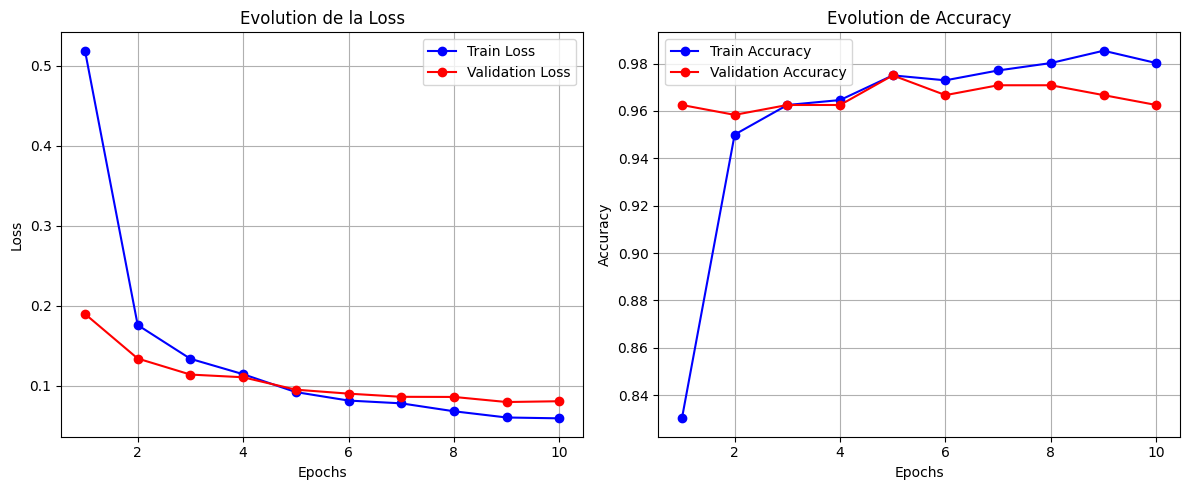

In [ ]:

import matplotlib.pyplot as plt

epochs = range(1, 11)

plt.figure(figsize=(12, 5))

# Courbe de Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, loss, 'b-o', label='Train Loss')
plt.plot(epochs, val_loss, 'r-o', label='Validation Loss')
plt.title('Evolution de la Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Courbe de Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, accuracy, 'b-o', label='Train Accuracy')
plt.plot(epochs, val_accuracy, 'r-o', label='Validation Accuracy')
plt.title('Evolution de Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

# Evaluation sur le dataset de test
test_gen.reset()

test_loss, test_accuracy = model.evaluate(test_gen)

print(f"Test Loss : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")


8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 212ms/step - accuracy: 0.9625 - loss: 0.0804
Test Loss : 0.0804
Test Accuracy : 96.25%


In [ ]:

import numpy as np

# Réinitialiser le générateur
test_gen.reset()

# Prédire les probabilités
y_pred_prob = model.predict(test_gen)

# Convertir les probabilités en classes
y_pred = np.argmax(y_pred_prob, axis=1)

# Récupérer les vraies classes
y_true = test_gen.classes

# Noms des classes dans l'ordre des indices
class_names = list(test_gen.class_indices.keys())

print("Classes :", class_names)
print("Prédictions :", y_pred[:10])
print("Vraies classes :", y_true[:10])


8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step
Classes : ['corba', 'donat', 'makarna']
Prédictions : [0 0 0 0 0 0 0 0 0 0]
Vraies classes : [0 0 0 0 0 0 0 0 0 0]


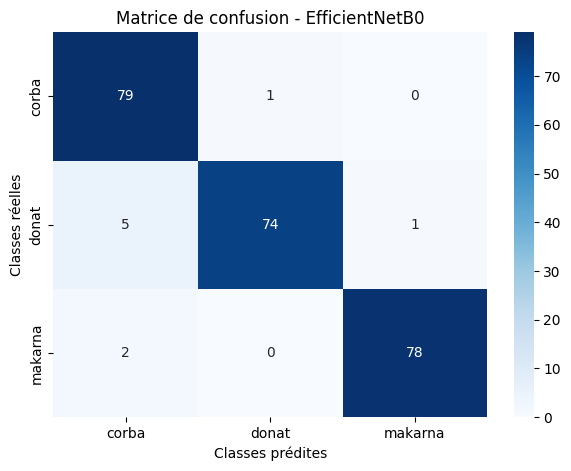

              precision    recall  f1-score   support

       corba       0.92      0.99      0.95        80
       donat       0.99      0.93      0.95        80
     makarna       0.99      0.97      0.98        80

    accuracy                           0.96       240
   macro avg       0.96      0.96      0.96       240
weighted avg       0.96      0.96      0.96       240



In [ ]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Calcul de la matrice de confusion
cm = confusion_matrix(y_true, y_pred)

# Affichage
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Classes prédites")
plt.ylabel("Classes réelles")
plt.title("Matrice de confusion - EfficientNetB0")
plt.show()

# Rapport de classification
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


In [ ]:

# Conserver les performances de Feature Extraction
accuracy_before = test_accuracy
loss_before = test_loss

# Nombre de paramètres entraînables avant dégel
params_before = sum(
    np.prod(v.shape) for v in model.trainable_weights
)

print("Accuracy avant Fine-Tuning :", accuracy_before)
print("Paramètres entraînables avant :", params_before)


Accuracy avant Fine-Tuning : 0.9624999761581421
Paramètres entraînables avant : 3843


In [ ]:

# Rendre la base potentiellement entraînable
base.trainable = True

# Geler toutes les couches sauf les 20 dernières
for layer in base.layers[:-20]:
    layer.trainable = False

# Dégeler les 20 dernières, sauf BatchNormalization
for layer in base.layers[-20:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

# Vérifier le nombre de couches entraînables
print("Couches entraînables dans la base :",
      sum(layer.trainable for layer in base.layers))


Couches entraînables dans la base : 15


In [ ]:

params_after = sum(
    np.prod(v.shape) for v in model.trainable_weights
)

print("Paramètres entraînables avant :", params_before)
print("Paramètres entraînables après :", params_after)
print("Paramètres supplémentaires :", params_after - params_before)


Paramètres entraînables avant : 3843
Paramètres entraînables après : 1346611
Paramètres supplémentaires : 1342768


In [ ]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [ ]:

history_fine = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5
)


Epoch 1/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 51s 811ms/step - accuracy: 0.9833 - loss: 0.0490 - val_accuracy: 0.9625 - val_loss: 0.0754
Epoch 2/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 451ms/step - accuracy: 0.9865 - loss: 0.0497 - val_accuracy: 0.9583 - val_loss: 0.0780
Epoch 3/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 566ms/step - accuracy: 0.9885 - loss: 0.0450 - val_accuracy: 0.9625 - val_loss: 0.0745
Epoch 4/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 446ms/step - accuracy: 0.9927 - loss: 0.0415 - val_accuracy: 0.9625 - val_loss: 0.0731
Epoch 5/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 445ms/step - accuracy: 0.9896 - loss: 0.0383 - val_accuracy: 0.9583 - val_loss: 0.0751


In [ ]:

test_gen.reset()

loss_after, accuracy_after = model.evaluate(test_gen)

print(f"Accuracy avant : {accuracy_before * 100:.2f}%")
print(f"Accuracy après : {accuracy_after * 100:.2f}%")

improvement = (accuracy_after - accuracy_before) * 100

print(f"Différence : {improvement:+.2f} points")


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 144ms/step - accuracy: 0.9583 - loss: 0.0751
Accuracy avant : 96.25%
Accuracy après : 95.83%
Différence : -0.42 points


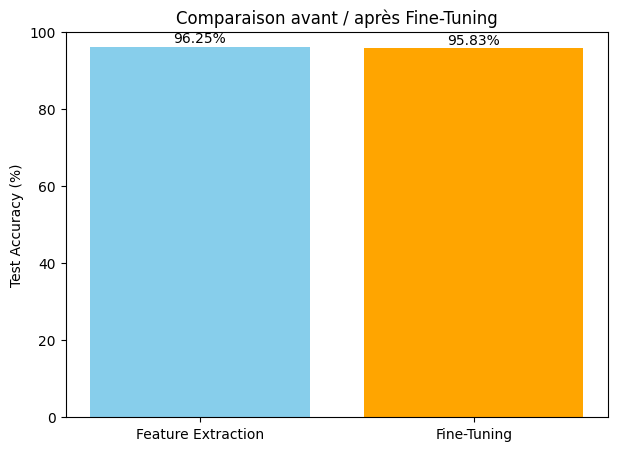

In [ ]:

import matplotlib.pyplot as plt

models_names = ['Feature Extraction', 'Fine-Tuning']
accuracies = [accuracy_before * 100, accuracy_after * 100]

plt.figure(figsize=(7, 5))
plt.bar(models_names, accuracies, color=['skyblue', 'orange'])

plt.ylabel("Test Accuracy (%)")
plt.title("Comparaison avant / après Fine-Tuning")
plt.ylim(0, 100)

for i, acc in enumerate(accuracies):
    plt.text(i, acc + 1, f"{acc:.2f}%", ha='center')

plt.show()


Pourquoi utiliser un learning rate de 1e-5 plutôt que 1e-3 ?
Parce que les poids d'EfficientNetB0 sont déjà pré-entraînés sur ImageNet.
- 1e-3 : mises à jour relativement importantes, adaptées à l'entraînement de la nouvelle tête de classification.
- 1e-5 : mises à jour plus petites, permettant d'ajuster progressivement les poids pré-entraînés sans détruire les connaissances acquises.

In [ ]:
""" Exercice 2 """

zip_path = "/content/PH2Dataset.zip"
extract_path = "/content/PH2dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction terminée !")

Extraction terminée !


In [ ]:

import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

# Chemins du dataset
root_path = "/content/PH2dataset/PH2Dataset"

images_path = os.path.join(root_path, "images")
masks_path = os.path.join(root_path, "masks")

IMG_SIZE = (256, 256)


In [ ]:

X = []
y = []

# Récupérer les noms communs aux images et masques
image_files = set(os.listdir(images_path))
mask_files = set(os.listdir(masks_path))

common_files = sorted(
    f for f in image_files.intersection(mask_files)
    if f.lower().endswith(".png")
)

for filename in common_files:

    # Charger l'image en RGB
    img = cv2.imread(os.path.join(images_path, filename))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Charger le masque en niveaux de gris
    mask = cv2.imread(
        os.path.join(masks_path, filename),
        cv2.IMREAD_GRAYSCALE
    )

    # Redimensionnement
    img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_LINEAR)
    mask = cv2.resize(
        mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST
    )

    # Normalisation des images : [0, 255] -> [0, 1]
    img = img.astype(np.float32) / 255.0

    # Binarisation des masques : 0 ou 1
    mask = (mask > 127).astype(np.float32)

    # Ajouter une dimension de canal au masque
    mask = np.expand_dims(mask, axis=-1)

    X.append(img)
    y.append(mask)

# Conversion en tableaux NumPy
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

print("Images :", X.shape)
print("Masques :", y.shape)
print("Valeurs des masques :", np.unique(y))


Images : (200, 256, 256, 3)
Masques : (200, 256, 256, 1)
Valeurs des masques : [0. 1.]


In [ ]:

# Première séparation : 70% train, 30% temporaire
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Deuxième séparation : 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)


In [ ]:

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_val   :", X_val.shape)
print("y_val   :", y_val.shape)

print("X_test  :", X_test.shape)
print("y_test  :", y_test.shape)

print("\nPlage des images :",
      X_train.min(), X_train.max())

print("Valeurs des masques :",
      np.unique(y_train))


X_train : (140, 256, 256, 3)
y_train : (140, 256, 256, 1)
X_val   : (30, 256, 256, 3)
y_val   : (30, 256, 256, 1)
X_test  : (30, 256, 256, 3)
y_test  : (30, 256, 256, 1)

Plage des images : 0.0 1.0
Valeurs des masques : [0. 1.]
